In [ ]:
!pip install numpy pandas matplotlib seaborn

In [ ]:
import os

# Include the full path including the filename
train_images_path = r"E:\lebika_training\MNIST\train-images-idx3-ubyte\train-images-idx3-ubyte"

with open(train_images_path, "rb") as file:
    image_data = file.read()

print("Data Type:", type(image_data))
print("Data Size:", len(image_data), "bytes")

Data Type: <class 'bytes'>
Data Size: 47040016 bytes


In [ ]:
with open(train_images_path, "rb") as file:
    image_data = file.read()

print("Data Type:", type(image_data))
print("Data Size:", len(image_data), "bytes")

Data Type: <class 'bytes'>
Data Size: 47040016 bytes


In [ ]:
import struct

magic, count, rows, cols = struct.unpack(
    ">IIII", image_data[:16]
)

print("Magic Number:", magic)
print("Number of Images:", count)
print("Image Height:", rows)
print("Image Width:", cols)

Magic Number: 2051
Number of Images: 60000
Image Height: 28
Image Width: 28


In [ ]:
import numpy as np

X_train = np.frombuffer(
    image_data,
    dtype=np.uint8,
    offset=16
)

X_train = X_train.reshape(count, rows, cols)

print("Training Images Shape:", X_train.shape)

Training Images Shape: (60000, 28, 28)


In [ ]:
train_labels_path = r"E:\lebika_training\MNIST\train-labels-idx1-ubyte\train-labels-idx1-ubyte"

In [ ]:
with open(train_labels_path, "rb") as file:
    label_data = file.read()

print("Label Data Type:", type(label_data))
print("Label File Size:", len(label_data))

Label Data Type: <class 'bytes'>
Label File Size: 60008


In [ ]:
magic, label_count = struct.unpack(
    ">II", label_data[:8]
)

y_train = np.frombuffer(
    label_data,
    dtype=np.uint8,
    offset=8
)

print("Number of Labels:", label_count)
print("Training Labels Shape:", y_train.shape)
print("First 10 Labels:", y_train[:10])

Number of Labels: 60000
Training Labels Shape: (60000,)
First 10 Labels: [5 0 4 1 9 2 1 3 1 4]


In [ ]:
test_images_path = r"E:\lebika_training\MNIST\t10k-images-idx3-ubyte\t10k-images-idx3-ubyte"

In [ ]:
with open(test_images_path, "rb") as file:
    test_image_data = file.read()
print("Testing Image Data Type:", type(test_image_data))
print("Testing Image File Size:", len(test_image_data))

Testing Image Data Type: <class 'bytes'>
Testing Image File Size: 7840016


In [ ]:
magic, test_count, rows, cols = struct.unpack(
    ">IIII", test_image_data[:16]
)

X_test = np.frombuffer(
    test_image_data,
    dtype=np.uint8,
    offset=16
)

X_test = X_test.reshape(test_count, rows, cols)

print("Testing Images Shape:", X_test.shape)

Testing Images Shape: (10000, 28, 28)


In [ ]:
test_labels_path = r"E:\lebika_training\MNIST\t10k-labels-idx1-ubyte\t10k-labels-idx1-ubyte"

In [ ]:
with open(test_labels_path, "rb") as file:
    test_label_data = file.read()

print("Testing Label File Size:", len(test_label_data))

Testing Label File Size: 10008


In [ ]:
magic, test_label_count = struct.unpack(
    ">II", test_label_data[:8]
)

y_test = np.frombuffer(
    test_label_data,
    dtype=np.uint8,
    offset=8
)

print("Testing Labels Shape:", y_test.shape)
print("First 10 Testing Labels:", y_test[:10])

Testing Labels Shape: (10000,)
First 10 Testing Labels: [7 2 1 0 4 1 4 9 5 9]


In [ ]:
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


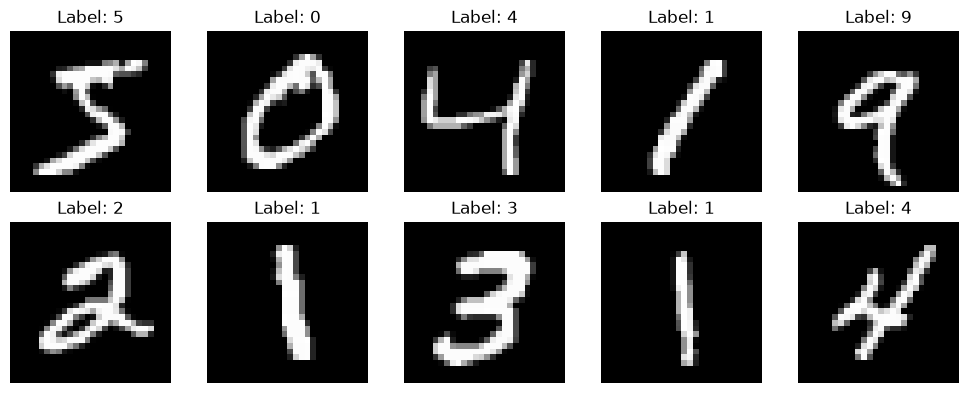

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Flatten images
X_train_flat = X_train.reshape(60000, 784)
X_test_flat = X_test.reshape(10000, 784)

# Normalize pixel values
X_train_normalized = X_train_flat.astype("float32") / 255.0
X_test_normalized = X_test_flat.astype("float32") / 255.0

print("Training data shape:", X_train_normalized.shape)
print("Testing data shape:", X_test_normalized.shape)

print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Training data shape: (60000, 784)
Testing data shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader, random_split

In [ ]:
X = torch.tensor(X_train_normalized, dtype=torch.float32)
y = torch.tensor(y_train, dtype=torch.long)

dataset = TensorDataset(X, y)

train_dataset, val_dataset = random_split(
    dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 54000
Validation samples: 6000


In [ ]:
class MNIST_MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNIST_MLP()

print(model)

MNIST_MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
epochs = 15

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    model.train()

    correct = 0
    total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = 100 * correct / total
    train_accuracies.append(train_accuracy)

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = 100 * correct / total
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/15] Training Accuracy: 87.95% Validation Accuracy: 92.90%
Epoch [2/15] Training Accuracy: 94.45% Validation Accuracy: 94.85%
Epoch [3/15] Training Accuracy: 95.98% Validation Accuracy: 96.00%
Epoch [4/15] Training Accuracy: 96.95% Validation Accuracy: 96.00%
Epoch [5/15] Training Accuracy: 97.45% Validation Accuracy: 96.17%
Epoch [6/15] Training Accuracy: 97.91% Validation Accuracy: 96.92%
Epoch [7/15] Training Accuracy: 98.26% Validation Accuracy: 96.93%
Epoch [8/15] Training Accuracy: 98.51% Validation Accuracy: 97.28%
Epoch [9/15] Training Accuracy: 98.81% Validation Accuracy: 97.25%
Epoch [10/15] Training Accuracy: 98.97% Validation Accuracy: 97.35%
Epoch [11/15] Training Accuracy: 99.12% Validation Accuracy: 97.48%
Epoch [12/15] Training Accuracy: 99.18% Validation Accuracy: 97.40%
Epoch [13/15] Training Accuracy: 99.35% Validation Accuracy: 97.52%
Epoch [14/15] Training Accuracy: 99.53% Validation Accuracy: 97.53%
Epoch [15/15] Training Accuracy: 99.55% Validation Accura

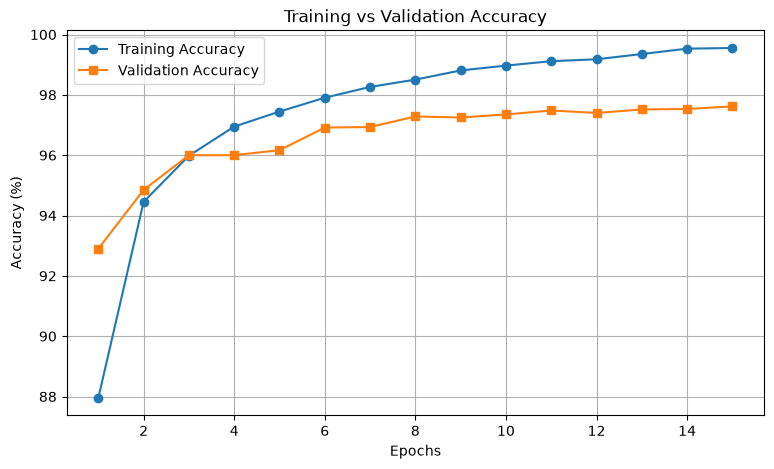

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, epochs + 1), train_accuracies,
         marker="o", label="Training Accuracy")

plt.plot(range(1, epochs + 1), val_accuracies,
         marker="s", label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
class Flexible_MLP(nn.Module):

    def __init__(self, hidden_sizes):
        super().__init__()

        layers = []
        input_size = 784

        for neurons in hidden_sizes:
            layers.append(nn.Linear(input_size, neurons))
            layers.append(nn.ReLU())
            input_size = neurons

        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


print("Flexible MLP model created successfully")

Flexible MLP model created successfully


In [ ]:
def train_model(hidden_sizes, learning_rate, epochs=15):

    torch.manual_seed(42)

    model = Flexible_MLP(hidden_sizes)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Training
    for epoch in range(epochs):

        model.train()

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

    # Evaluate training accuracy
    model.eval()

    train_correct = 0
    train_total = 0

    with torch.no_grad():

        for images, labels in train_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

    train_accuracy = 100 * train_correct / train_total

    # Evaluate validation accuracy
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = 100 * val_correct / val_total

    return train_accuracy, val_accuracy


print("Training function created successfully")

Training function created successfully


In [ ]:
experiment_results = []

learning_rates = [0.001, 0.01, 0.1]

for lr in learning_rates:

    train_acc, val_acc = train_model(
        hidden_sizes=[128, 64],
        learning_rate=lr,
        epochs=15
    )

    experiment_results.append({
        "Experiment": "Learning Rate",
        "Configuration": str(lr),
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

    print(
        f"Learning Rate: {lr} | "
        f"Training Accuracy: {train_acc:.2f}% | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Learning Rate: 0.001 | Training Accuracy: 99.65% | Validation Accuracy: 97.22%
Learning Rate: 0.01 | Training Accuracy: 98.41% | Validation Accuracy: 96.32%
Learning Rate: 0.1 | Training Accuracy: 36.89% | Validation Accuracy: 38.07%


In [ ]:
hidden_sizes_list = [32, 64, 128, 256]

for neurons in hidden_sizes_list:

    train_acc, val_acc = train_model(
        hidden_sizes=[neurons, neurons],
        learning_rate=0.001,
        epochs=15
    )

    experiment_results.append({
        "Experiment": "Hidden Layer Size",
        "Configuration": str(neurons),
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

    print(
        f"Neurons: {neurons} | "
        f"Training Accuracy: {train_acc:.2f}% | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Neurons: 32 | Training Accuracy: 97.87% | Validation Accuracy: 95.85%
Neurons: 64 | Training Accuracy: 99.31% | Validation Accuracy: 97.22%
Neurons: 128 | Training Accuracy: 99.79% | Validation Accuracy: 97.22%
Neurons: 256 | Training Accuracy: 99.61% | Validation Accuracy: 97.60%


In [ ]:
hidden_layer_counts = [1, 2, 3]

for count in hidden_layer_counts:

    train_acc, val_acc = train_model(
        hidden_sizes=[128] * count,
        learning_rate=0.001,
        epochs=15
    )

    experiment_results.append({
        "Experiment": "Number of Hidden Layers",
        "Configuration": str(count),
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

    print(
        f"Hidden Layers: {count} | "
        f"Training Accuracy: {train_acc:.2f}% | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Hidden Layers: 1 | Training Accuracy: 99.69% | Validation Accuracy: 97.55%
Hidden Layers: 2 | Training Accuracy: 99.79% | Validation Accuracy: 97.22%
Hidden Layers: 3 | Training Accuracy: 99.79% | Validation Accuracy: 97.68%


In [ ]:
results_df = pd.DataFrame(experiment_results)

results_df = results_df.round(2)

print(results_df.to_string(index=False))

             Experiment Configuration  Training Accuracy  Validation Accuracy
          Learning Rate         0.001              99.65                97.22
          Learning Rate          0.01              98.41                96.32
          Learning Rate           0.1              36.89                38.07
      Hidden Layer Size            32              97.87                95.85
      Hidden Layer Size            64              99.31                97.22
      Hidden Layer Size           128              99.79                97.22
      Hidden Layer Size           256              99.61                97.60
Number of Hidden Layers             1              99.69                97.55
Number of Hidden Layers             2              99.79                97.22
Number of Hidden Layers             3              99.79                97.68


In [ ]:
best_results = results_df.loc[
    results_df.groupby("Experiment")["Validation Accuracy"].idxmax()
]

print("Best Configuration for Each Experiment:")
print(best_results.to_string(index=False))

Best Configuration for Each Experiment:
             Experiment Configuration  Training Accuracy  Validation Accuracy
      Hidden Layer Size           256              99.61                97.60
          Learning Rate         0.001              99.65                97.22
Number of Hidden Layers             3              99.79                97.68


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import pandas as pd

In [ ]:
X_test_tensor = torch.tensor(
    X_test_normalized,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Test dataset prepared:", len(test_dataset))

Test dataset prepared: 10000


In [ ]:
class Activation_MLP(nn.Module):

    def __init__(self, activation):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            activation(),

            nn.Linear(128, 64),
            activation(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
def train_activation_model(activation, epochs=15):

    torch.manual_seed(42)

    model = Activation_MLP(activation)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    start_time = time.time()
    time_to_90 = None

    for epoch in range(epochs):

        model.train()

        correct = 0
        total = 0

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels) 

            loss.backward()

            optimizer.step()

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_accuracy = 100 * correct / total

        if train_accuracy >= 90 and time_to_90 is None:
            time_to_90 = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Training Accuracy: {train_accuracy:.2f}%"
        )

    # Calculate final test accuracy
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    test_accuracy = 100 * correct / total

    total_time = time.time() - start_time

    if time_to_90 is None:
        time_to_90 = "Not reached"

    return time_to_90, test_accuracy, total_time

In [ ]:
activation_results = []

activation_functions = {
    "Sigmoid": nn.Sigmoid,
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh
}

for name, activation in activation_functions.items():

    print("\nTraining:", name)

    time_90, test_acc, total_time = train_activation_model(
        activation,
        epochs=15
    )

    activation_results.append({
        "Activation Function": name,
        "Time to 90% Accuracy (seconds)": time_90,
        "Final Test Accuracy (%)": test_acc,
        "Total Training Time (seconds)": total_time
    })


Training: Sigmoid
Epoch 1/15 - Training Accuracy: 74.91%
Epoch 2/15 - Training Accuracy: 91.84%
Epoch 3/15 - Training Accuracy: 93.89%
Epoch 4/15 - Training Accuracy: 95.13%
Epoch 5/15 - Training Accuracy: 96.02%
Epoch 6/15 - Training Accuracy: 96.63%
Epoch 7/15 - Training Accuracy: 97.18%
Epoch 8/15 - Training Accuracy: 97.53%
Epoch 9/15 - Training Accuracy: 97.90%
Epoch 10/15 - Training Accuracy: 98.21%
Epoch 11/15 - Training Accuracy: 98.42%
Epoch 12/15 - Training Accuracy: 98.66%
Epoch 13/15 - Training Accuracy: 98.84%
Epoch 14/15 - Training Accuracy: 99.01%
Epoch 15/15 - Training Accuracy: 99.18%

Training: ReLU
Epoch 1/15 - Training Accuracy: 88.13%
Epoch 2/15 - Training Accuracy: 94.57%
Epoch 3/15 - Training Accuracy: 96.13%
Epoch 4/15 - Training Accuracy: 96.91%
Epoch 5/15 - Training Accuracy: 97.44%
Epoch 6/15 - Training Accuracy: 98.06%
Epoch 7/15 - Training Accuracy: 98.28%
Epoch 8/15 - Training Accuracy: 98.60%
Epoch 9/15 - Training Accuracy: 98.88%
Epoch 10/15 - Training 

In [ ]:
activation_df = pd.DataFrame(activation_results)

print(activation_df.round(2).to_string(index=False))

Activation Function  Time to 90% Accuracy (seconds)  Final Test Accuracy (%)  Total Training Time (seconds)
            Sigmoid                            4.49                    97.56                          34.66
               ReLU                            3.75                    97.73                          24.26
               Tanh                            3.05                    97.80                          22.71
